# HSPC_RNA · ATLAS Table 3 · T3 Trajectory & T4 Future-fate Proxy

This notebook trains a **new three-modality ATLAS model (Mc/Mu/Ms)**, evaluates **T3 POA/POAUC**, and tests **T4 train-terminal-reference absorption**. It uses the original V4 data filenames but replaces TIDE/CORAL with the current `atlas.model.ATLAS` plus a new independent HSPC trainer.

**Scientific caveat:** T4 target labels are derived from current annotated cell types (`future_map`), not experimental future-cell outcomes. Unlike the old V4 notebook, held-out test cell labels are not used to construct terminal reference populations or tune settings. Reproduced scores are **not directly comparable** to paper Table 3 until the original protocol is verified.

The notebook adds files only under `src/atlas/hspc_table3.py`, `notebooks/table3_hspc/` and `results/table3_hspc/`—it does **not** change your running E1-E4 experiment.

## 1. Environment and training settings

In [1]:
from pathlib import Path
import sys, json
import pandas as pd

PROJECT_ROOT = Path('/data5/zhangye/ATLAS')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from atlas.hspc_table3 import HSPCConfig, DATASET_FILES, load_hspc_data, run_hspc

DATASET_NAME = 'HSPC_RNA'
DATA_ROOT = Path('/data5/zhangye/VelocityBench/data')
OUTPUT_ROOT = PROJECT_ROOT / 'results' / 'table3_hspc'
ANNOTATION_JSON = PROJECT_ROOT / 'configs' / f'{DATASET_NAME}_annotations.json'
QUICK = True     # Smoke test first; change to False for 80/40/60 epoch full training.
DEVICE = 'cuda:0'
SEED = 1234
TOP_N_GENES = 2000

cfg = HSPCConfig(dataset=DATASET_NAME, data_root=str(DATA_ROOT),
                 output_root=str(OUTPUT_ROOT),device=DEVICE,
                 seed=SEED,top_n_genes=TOP_N_GENES,quick=QUICK)
assert ANNOTATION_JSON.exists(), f'Missing {ANNOTATION_JSON}. Extract the package into the ATLAS root first.'
annotations=json.loads(ANNOTATION_JSON.read_text())
print('Data files:', [str(DATA_ROOT/p) for p in DATASET_FILES[DATASET_NAME]])
print('Annotation file:',ANNOTATION_JSON)
print('Epochs:', '2/1/2 (smoke)' if QUICK else '80/40/60 (full)')

Data files: ['/data5/zhangye/VelocityBench/data/3423-MV-2-8489-MV-1-GSM5460410_adata_postpro_concat.h5ad', '/data5/zhangye/VelocityBench/data/3423-MV-2-8489-MV-1-GSM5460410_adata_atac_postpro_concat.h5ad']
Annotation file: /data5/zhangye/ATLAS/configs/HSPC_RNA_annotations.json
Epochs: 2/1/2 (smoke)


## 2. Inspect data layout and annotation mappings before training

In [2]:
import anndata as ad
for file_name in DATASET_FILES[DATASET_NAME]:
    p = DATA_ROOT / file_name
    if not p.exists():
        raise FileNotFoundError(f'{p} (original V4 HSPC data is not included in the code bundle)')
    raw = ad.read_h5ad(p, backed='r')
    print(p.name, 'cells=',raw.n_obs,'features=',raw.n_vars,
          'layers=',list(raw.layers.keys()),'obs=',list(raw.obs.columns[:12]))
    if cfg.label_key in raw.obs:
        print(raw.obs[cfg.label_key].astype(str).value_counts().head(25))
    if getattr(raw,'file',None) is not None: raw.file.close()
print('Stage map:', annotations['stage_order_map'])
print('Fate map:', annotations['future_map'])
print('Terminals:', annotations['terminal_types'])

3423-MV-2-8489-MV-1-GSM5460410_adata_postpro_concat.h5ad cells= 27841 features= 1044 layers= ['Ms', 'Mu', 'spliced', 'unspliced'] obs= ['total_unspliced', 'total_spliced', 'log1p_total_unspliced', 'log1p_total_spliced', 'fraction_u', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt']
3423-MV-2-8489-MV-1-GSM5460410_adata_atac_postpro_concat.h5ad cells= 27841 features= 1044 layers= ['Mc'] obs= ['n_counts', 'batch']
Stage map: {'HSC': 0, 'LMPP': 1, 'CMP': 1, 'GMP': 1, 'MEP': 1, 'Prog B': 1, 'Prog DC': 1, 'Prog MK': 1, 'DC': 2, 'Granulocyte': 2, 'Erythrocyte': 2, 'Megakaryocyte': 2, 'Platelet': 2, 'Mast Cells': 2}
Fate map: {'LMPP': 'lymphoid_dc', 'Prog B': 'lymphoid_dc', 'Prog DC': 'lymphoid_dc', 'DC': 'lymphoid_dc', 'CMP': 'myeloid', 'GMP': 'myeloid', 'Granulocyte': 'myeloid', 'Mast Cells': 'myeloid', 'MEP': 'ery_platelet', 'Prog MK': 'ery_platelet', 'Megakaryocyte': 'ery_platelet

## 3. Train ATLAS (T1/T2 representation → T3 TimeHead + lag → T4 velocity)

The model is trained **without test-stage or test-fate supervision**. Train-stage annotations are used only to decide the otherwise ambiguous time direction during evaluation. Terminal reference labels are taken from training cells only.

This cell performs training and saves separate checkpoints for each phase; it will not overwrite an already completed result directory.

In [4]:
cfg.label_key = "leiden"

summary, RUN_DIR = run_hspc(cfg, annotations)
print('All outputs:', RUN_DIR)

[HSPC_RNA] cells=27841 genes=1044 train=22272 test=5569
Unmapped stage labels: []
Unmapped fate labels: ['HSC']
[HSPC_RNA] phase1 1/2 loss=4.7818
[HSPC_RNA] phase1 2/2 loss=3.7036
[HSPC_RNA] phase2 1/1 loss=4.8439


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


[teacher] phase3 epoch=1, anchors=4000
[HSPC_RNA] phase3 1/2 loss=4.2266
[HSPC_RNA] phase3 2/2 loss=4.0158


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


{
  "dataset": "HSPC_RNA",
  "seed": 1234,
  "T3": {
    "POA": 0.5557985384962681,
    "POAUC": 0.5626403964934075,
    "n_eval": 5569,
    "stages": 3,
    "orientation_from_train_stage_only": 1,
    "train_stage_spearman_for_orientation": 0.09531599542048327,
    "time_source": "trained_time_head",
    "reference_labels_for_training_loss": false,
    "test_labels_for_orientation": false
  },
  "T4": {
    "F1": 0.5098318076997789,
    "AUROC": 0.7978013475202627,
    "n_eval": 2664,
    "classes": [
      "ery_platelet",
      "lymphoid_dc",
      "myeloid"
    ],
    "target": "celltype_derived_fate_proxy",
    "fate_labels_used_to_train_velocity": false,
    "heldout_eval_cells_overlap_terminal_reference": false,
    "time_only_F1": 0.5013534382373096,
    "time_only_AUROC": 0.798662483139363
  },
  "annotation_protocol": "train-only stage orientation; train-only terminal prototypes; heldout test",
  "warning": "Fate proxy from celltype, NOT real future longitudinal measurement; n

## 4. Read T3 / T4 results and compare with paper reference

The paper values below are reference numbers, **not** automatically reproduced here; label-protocol differences mean direct numeric comparisons are diagnostic only.

,Paper reference,This run (heldout/proxy)
POA,0.701,0.555799
POAUC,0.717,0.562640
F1,0.602,0.509832
AUROC,0.770,0.797801


T3 test n: 5569 T4 test n: 2664
T4 time-only baseline: F1 = 0.5013534382373096 AUROC = 0.798662483139363


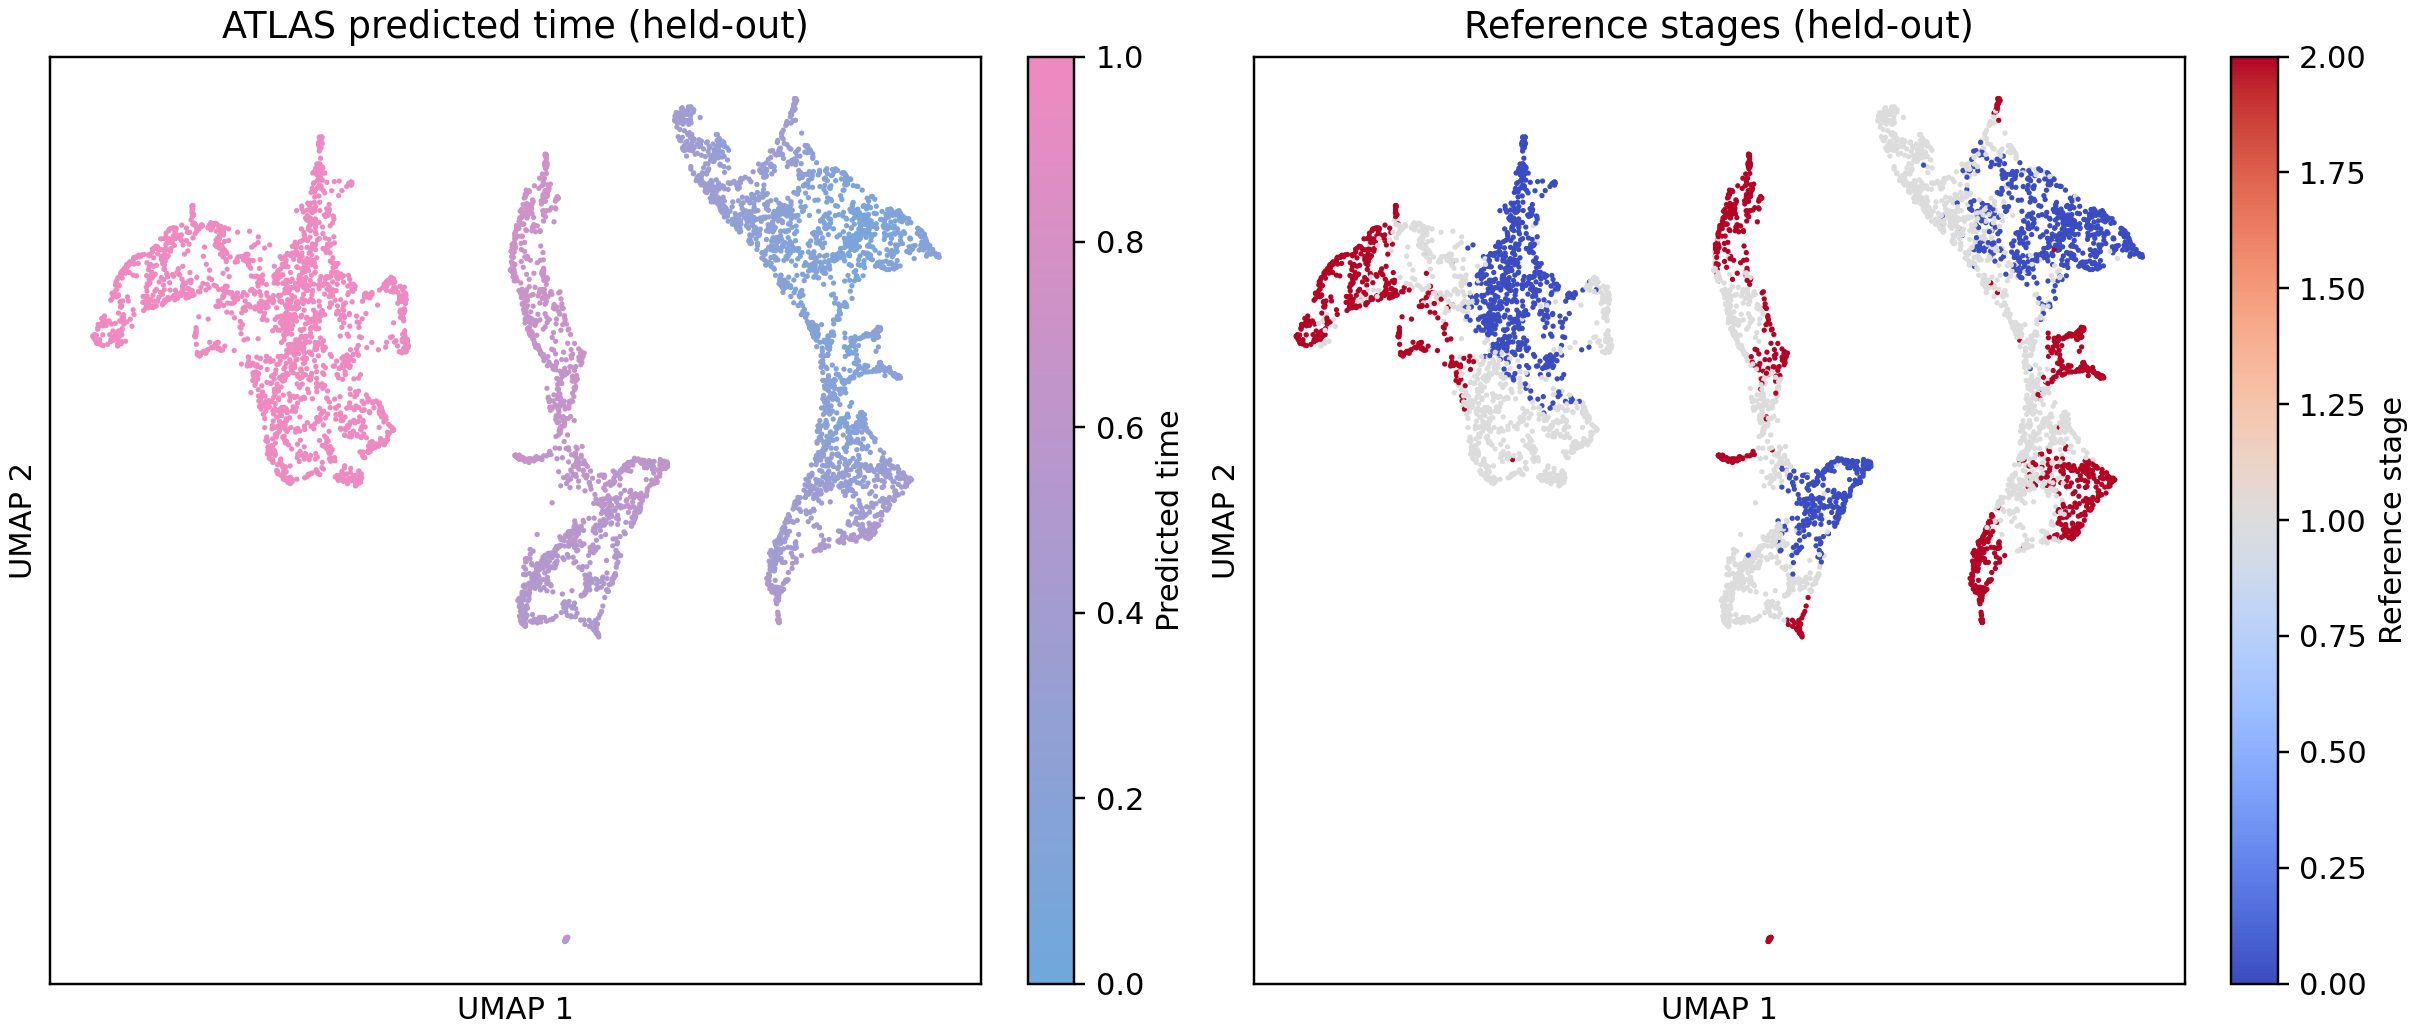

In [5]:
from IPython.display import display, Image
m3=json.loads((RUN_DIR/'T3_metrics.json').read_text())
m4=json.loads((RUN_DIR/'T4_metrics.json').read_text())
paper={'POA':0.701,'POAUC':0.717,'F1':0.602,'AUROC':0.77}
compare=pd.DataFrame({'Paper reference':paper,
                     'This run (heldout/proxy)':{'POA':m3['POA'],'POAUC':m3['POAUC'],
                                                    'F1':m4['F1'],'AUROC':m4['AUROC']}})
display(compare)
print('T3 test n:', m3['n_eval'], 'T4 test n:',m4['n_eval'])
print('T4 time-only baseline: F1 =', m4.get('time_only_F1'), 'AUROC =',m4.get('time_only_AUROC'))
display(Image(filename=str(RUN_DIR/'T3_trajectory.png')))

## 5. Inspect T4 predictions and leakage/coverage diagnostics

In [8]:
display(pd.read_csv(RUN_DIR / 'T4_heldout_predictions.csv').head(10))
print(json.dumps(json.loads((RUN_DIR / 'T4_transition_diagnostics.json').read_text()),indent=2))
manifest=pd.read_csv(RUN_DIR/'split_manifest.csv')
print('Train:',sum(manifest.partition=='train'),'Test:',sum(manifest.partition=='test'))
assert manifest.cell_id.is_unique
print('T4 reference contains ONLY train terminal cells; test fate labels are scoring-only.')

,cell_id,true_fate_proxy,p_ery_platelet,p_lymphoid_dc,p_myeloid
0,AAACATGCAGTATGTT-1-Multiome 1,lymphoid_dc,2.702323e-07,9.963194e-01,3.680369e-03
1,AAACCGAAGCATCCAG-1-Multiome 1,ery_platelet,1.000000e+00,2.469860e-10,2.469860e-10
2,AAACCGCGTTGTGACA-1-Multiome 1,myeloid,7.096006e-01,4.305606e-02,2.473433e-01
3,AAACGCGCATAATTGC-1-Multiome 1,ery_platelet,9.999453e-01,1.000359e-10,5.468883e-05
4,AAAGCCCGTTCAAGCA-1-Multiome 1,lymphoid_dc,6.103635e-08,9.999999e-01,6.103635e-08
5,AAAGCCGCAATAGCCC-1-Multiome 1,myeloid,1.710765e-03,1.505639e-01,8.477253e-01
6,AAAGCGGGTGAGACTC-1-Multiome 1,myeloid,8.419256e-01,5.521802e-02,1.028564e-01
7,AAAGCTTGTTAGTACG-1-Multiome 1,lymphoid_dc,4.410541e-03,6.141497e-01,3.814397e-01
8,AAAGGACGTGTTTCAC-1-Multiome 1,ery_platelet,1.000000e+00,1.000000e-10,1.000000e-10
9,AAAGGACGTTAGGACC-1-Multiome 1,ery_platelet,9.969102e-01,1.523732e-04,2.937401e-03


{
  "n_reference": 22272,
  "n_terminal": 5458,
  "n_queries": 2664,
  "n_unresolved_prior_fallback": 177,
  "transition_rows": 22272,
  "transition_nnz": 535088,
  "terminal_reference_classes": {
    "ery_platelet": 3873,
    "lymphoid_dc": 235,
    "myeloid": 1350
  }
}
Train: 22272 Test: 5569
T4 reference contains ONLY train terminal cells; test fate labels are scoring-only.


## 6. Optional: combined table for all HSPC datasets

In [9]:
# Run this cell after completing all three notebooks.
from subprocess import run
run([sys.executable,str(PROJECT_ROOT/'experiments/summarize_table3_hspc.py'),
     '--root',str(OUTPUT_ROOT)],check=True)

 dataset  seed  mode      POA    POAUC       F1    AUROC  T4_time_only_F1  T4_time_only_AUROC  T3_n_eval  T4_n_eval                                                            output
 HSPC_2M  1234 quick 0.624356 0.642491 0.609583 0.816835         0.624087            0.814146       3533       1751  /data5/zhangye/ATLAS/results/table3_hspc/HSPC_2M/quick/seed_1234
HSPC_MAC  1234 quick 0.613905 0.622415 0.529702 0.784255         0.533039            0.780613       1982        890 /data5/zhangye/ATLAS/results/table3_hspc/HSPC_MAC/quick/seed_1234
HSPC_RNA  1234 quick 0.555799 0.562640 0.509832 0.797801         0.501353            0.798662       5569       2664 /data5/zhangye/ATLAS/results/table3_hspc/HSPC_RNA/quick/seed_1234
Saved /data5/zhangye/ATLAS/results/table3_hspc/Table3_reproduced_summary.csv


CompletedProcess(args=['/home/zhangye/anaconda3/envs/scmrdr/bin/python', '/data5/zhangye/ATLAS/experiments/summarize_table3_hspc.py', '--root', '/data5/zhangye/ATLAS/results/table3_hspc'], returncode=0)